## BLI-GAT model
## Figure 8, Figure S8, Figure 5
By changing the molecule SMILES, eluent SMILES, or the ratios in input file(pred_list.csv), you can predict the retention factor value for a molecule of your choice.

In [1]:
import os
import sys
import string
from contextlib import contextmanager
from fractions import Fraction

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Descriptors
from torch_geometric.loader import DataLoader

# Run this notebook from Predictive_models/model_validation 
NOTEBOOK_DIR = os.path.abspath('')                                   # /DTLC/Predictive_models/model_validation
BASE = os.path.dirname(NOTEBOOK_DIR)                                 # /DTLC/Predictive_models
DTLC_ROOT = os.path.dirname(BASE)                                    # /DTLC
TRAINING_DIR = os.path.join(BASE, 'Training')
RF_DIR = os.path.join(TRAINING_DIR, 'DB', 'Rf')
MODEL_PATH = os.path.join(BASE, 'Trained_models', 'GAT_BLI')

sys.path.insert(0, os.path.join(BASE, 'Model_architecture'))    # GAT_model_architecture
sys.path.insert(0, TRAINING_DIR)                                 # make_graph_dataloader

from GAT_model_architecture import GAT_BLI

ELUENT_NAMES = {'CCCCCC': 'Hex', 'CCOC(C)=O': 'EA', 'ClCCl': 'DCM', 'CO': 'MeOH'}


@contextmanager
def _in_training_dir():

    # make_graph_dataloader and the standardization files use paths relative to Training/
    old = os.getcwd()
    os.chdir(TRAINING_DIR)
    try:
        yield
    finally:
        os.chdir(old)

In [2]:
def inverse_standardization(pred_nd_array, mean, std):
    return pred_nd_array * std + mean


# ratio conversion
def vol_2_mol_ratio(df, elu1_col='elu1_smiles', elu2_col='elu2_smiles'):
    df = df.copy()
    elu_inform = pd.read_csv('./DB/data_process/eluent_standard.csv')
    d_converter = dict(zip(elu_inform['hex_Smiles'], elu_inform['density'].astype(float)))

    for col in [elu1_col, elu2_col]:
        unknown = set(df[col].dropna()) - set(d_converter)
        if unknown:
            raise ValueError(f'The density is missing in eluent_standard.csv: {unknown}')

    mol1 = [r * d_converter[s] / Descriptors.MolWt(Chem.MolFromSmiles(s)) if pd.notna(s) else r
            for s, r in zip(df[elu1_col], df['ratio1'])]
    mol2 = [r * d_converter[s] / Descriptors.MolWt(Chem.MolFromSmiles(s)) if pd.notna(s) else r
            for s, r in zip(df[elu2_col], df['ratio2'])]
    mol1, mol2 = np.array(mol1), np.array(mol2)

    # mol ratio normalization
    ratio_total = mol1 + mol2
    df['ratio1'] = np.round(mol1 / ratio_total, 6)
    df['ratio2'] = np.round(mol2 / ratio_total, 6)
    return df

In [3]:
def make_graph_predict(model, ckpt, csv_name):

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = model.to(device)
    opt_ckpt = torch.load((ckpt + '/opt_checkpoint.pt'), map_location=device)
    model.load_state_dict(opt_ckpt['model_state_dict'])


    mean = np.load('./standardization/mean.npy')
    std = np.load('./standardization/std.npy')


    # ====================================================
    from make_graph_dataloader import MolToGraph
    from make_graph_dataloader import TripleGraphDataset
    path_raw = './DB/Rf'
    print('>>> making graph...')

    for suffix in ['compound', 'elu1', 'elu2']:
        cached = os.path.join(path_raw, 'processed', 'experimental', f'{csv_name}_{suffix}.pt')
        if os.path.exists(cached):
            os.remove(cached)

    _org_np_load = np.load
    # _old_root = '/home/ufslab223/Shared/KSW/torch_geometric/TLC_RF/'

    # def _local_np_load(file, *args, **kwargs):
    # #     if isinstance(file, str) and file.startswith(_old_root) and not os.path.exists(file):
    # #         file = os.path.join(os.getcwd(), file[len(_old_root):])
    # #     return _org_np_load(file, *args, **kwargs)
    # np.load = _local_np_load
    try:
        compound_trend_set = MolToGraph('Smiles', path_raw, csv_name, f'experimental/{csv_name}_compound.pt', molecular_param = False, augment = True)
        elu1_trend_set = MolToGraph('elu1_smiles', path_raw, csv_name, f'experimental/{csv_name}_elu1.pt', molecular_param = False, augment = True)
        elu2_trend_set = MolToGraph('elu2_smiles', path_raw, csv_name, f'experimental/{csv_name}_elu2.pt', molecular_param = False, augment = True)
    finally:
        np.load = _org_np_load

    # ====================================================
    print('>>> collecting: compound, eluent graph...')
    graph_trend_set = TripleGraphDataset(
        compound_trend_set,
        elu1_trend_set,
        elu2_trend_set
    )

    #=====================================================
    print('>>> making: dataloader...')
    trend_loader = DataLoader(graph_trend_set, batch_size =500, shuffle=False)

    # ====================================================
    print('>>> predicting...')

    trend_pred=[]
    trend_id=[]
    model.eval()
    with torch.no_grad():
        for com_trend, elu1_trend, elu2_trend in trend_loader:
            trend_id.append(com_trend.sample_id)
            com_trend_batch = com_trend.to(device)
            elu1_trend_batch = elu1_trend.to(device)
            elu2_trend_batch = elu2_trend.to(device)
            pred = model(com_trend_batch, elu1_trend_batch, elu2_trend_batch)
            trend_pred.append(pred.cpu())

    trend_pred = np.vstack(trend_pred)
    trend_pred = inverse_standardization(trend_pred, mean, std)
    trend_pred = trend_pred.reshape(-1)
    print('>> Done!')
    return trend_pred

In [4]:
def predict_vol_ratio_csv(input_csv, output_csv=None):
    # Input: csv with columns Smiles, elu1_smiles, elu2_smiles, ratio1, ratio2 (volume ratio), [Rf]
    # Relative paths are resolved from Training/ (e.g. './DB/Rf/pred_result.csv')
    input_csv = os.path.abspath(input_csv)
    input_df = pd.read_csv(input_csv)

    required_columns = ['Smiles', 'elu1_smiles', 'elu2_smiles', 'ratio1', 'ratio2']
    missing_columns = [column for column in required_columns if column not in input_df.columns]
    if missing_columns:
        raise ValueError(f'missing column for an Input file: {missing_columns}')

    name = os.path.splitext(os.path.basename(input_csv))[0]
    if output_csv is None:
        output_csv = f'./DB/Rf/{name}_molfrac_predicted.csv'

    with _in_training_dir():
        # vol/vol to mol/mol
        model_input = vol_2_mol_ratio(input_df[required_columns + (['Rf'] if 'Rf' in input_df.columns else [])])
        if 'Rf' not in model_input.columns:
            model_input['Rf'] = np.nan
        model_input['sample_id'] = np.arange(len(model_input))

        model_input_name = f'{name}_molfrac_input.csv'
        model_input.to_csv(f'./DB/Rf/{model_input_name}', index=False)

        predict = make_graph_predict(model=GAT_BLI(), ckpt=MODEL_PATH, csv_name=model_input_name)
        predict = np.clip(predict, 0, 1)
        if len(predict) != len(input_df):
            raise ValueError(f'input column #({len(input_df)}) and prediction column # ({len(predict)})is different.')

        result = input_df.copy()
        result['BLI_GAT_Rf'] = predict
        result.to_csv(output_csv, index=False)
        print(f'>> saved: {(output_csv)}')
    return result

In [5]:
## plot

def plot_functional(result, n_cols=4):
    # one panel per compound, x = EA volume fraction (pred_list.csv: evenly spaced ratios)
    molecules = result['Smiles'].unique()
    n_mol = len(molecules)
    n_rows = int(np.ceil(n_mol / n_cols))
    labels = list(string.ascii_lowercase)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.6 * n_rows), sharex=True, sharey=True)
    axes = np.array(axes).reshape(-1)

    for idx, (ax, smi) in enumerate(zip(axes, molecules)):
        sub = result[result['Smiles'] == smi].sort_values('ratio2')
        ea_ratio = sub['ratio2']

        ax.plot(ea_ratio, sub['Rf'], 'o-', color='black', label='Expt.')
        ax.plot(ea_ratio, sub['BLI_GAT_Rf'], 'o-', color='black', markerfacecolor='white', label='Pred.')

        ax.set_title(f'({labels[idx]})', fontsize=10, fontweight='bold')

        ax.set_xlim(-0.05, 1.05)
        ax.set_ylim(-0.05, 1.05)
        ax.set_xticks(np.arange(0, 1.1, 0.2))
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8, loc='best')

    for ax in axes[n_mol:]:
        ax.axis('off')

    for ax in axes[(n_rows - 1) * n_cols:]:
        ax.set_xlabel('EA')
    for ax in axes[::n_cols]:
        ax.set_ylabel('Rf')

    plt.tight_layout()
    plt.show()


def to_int_ratio(r1, r2, max_den=20):
    # 0.75:0.25 -> '3:1', 0.990099:0.009901 -> '100:1'
    if r1 >= r2:
        f = Fraction(r1 / r2).limit_denominator(max_den)
        return f'{f.numerator}:{f.denominator}'
    f = Fraction(r2 / r1).limit_denominator(max_den)
    return f'{f.denominator}:{f.numerator}'


def plot_solvent(result, n_cols=2):
    # one panel per (Smiles, elu1_smiles, elu2_smiles), x = integer volume ratio (pred_list2.csv)
    group_cols = ['Smiles', 'elu1_smiles', 'elu2_smiles']
    groups = list(result.groupby(group_cols, sort=False))
    n_grp = len(groups)
    n_rows = int(np.ceil(n_grp / n_cols))

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.6 * n_rows), sharey=True)
    axes = np.array(axes).reshape(-1)

    for idx, (ax, ((smi, elu1, elu2), sub)) in enumerate(zip(axes, groups)):
        sub = sub.sort_values('ratio2')
        x = np.arange(len(sub))
        xticklabels = [to_int_ratio(r1, r2) for r1, r2 in zip(sub['ratio1'], sub['ratio2'])]

        ax.plot(x, sub['Rf'], 'o-', color='black', label='Expt.')
        ax.plot(x, sub['BLI_GAT_Rf'], 'o-', color='black', markerfacecolor='white', label='Pred.')

        ax.set_title(f'{idx + 1}', fontsize=10, fontweight='bold')

        ax.set_xticks(x)
        ax.set_xticklabels(xticklabels)
        ax.set_xlim(-0.3, len(sub) - 0.7)
        ax.set_ylim(-0.05, 1.05)
        ax.set_xlabel(f'{ELUENT_NAMES.get(elu1, elu1)}:{ELUENT_NAMES.get(elu2, elu2)}')
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8, loc='best')

    for ax in axes[n_grp:]:
        ax.axis('off')

    for ax in axes[::n_cols]:
        ax.set_ylabel('Rf')

    plt.tight_layout()
    plt.show()

## Prediction

## Figure 8, S8

In [6]:
input_csv = os.path.join(DTLC_ROOT, 'Predictive_models/model_validation', 'pred_list1.csv')
result1 = predict_vol_ratio_csv(input_csv, output_csv='./pred_result.csv')
result1.head(15)

>>> making graph...


Processing...


  0%|          | 0/176 [00:00<?, ?it/s]

Done!
Processing...


  0%|          | 0/176 [00:00<?, ?it/s]

Done!
Processing...


  0%|          | 0/176 [00:00<?, ?it/s]

Done!


>>> collecting: compound, eluent graph...
>>> making: dataloader...
>>> predicting...
>> Done!
>> saved: ./pred_result.csv


,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,BLI_GAT_Rf
0,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,1.0,0.0,0.04,0.011619
1,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.9,0.1,0.19,0.086426
2,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.8,0.2,0.49,0.205202
3,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.7,0.3,0.62,0.430137
4,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.6,0.4,0.67,0.596444
5,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.5,0.5,0.73,0.720846
6,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.4,0.6,0.85,0.798331
7,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.3,0.7,0.85,0.841115
8,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.2,0.8,0.85,0.880774
9,C1=CC=C(C=C1)N,CCCCCC,CCOC(C)=O,0.1,0.9,0.92,0.916921


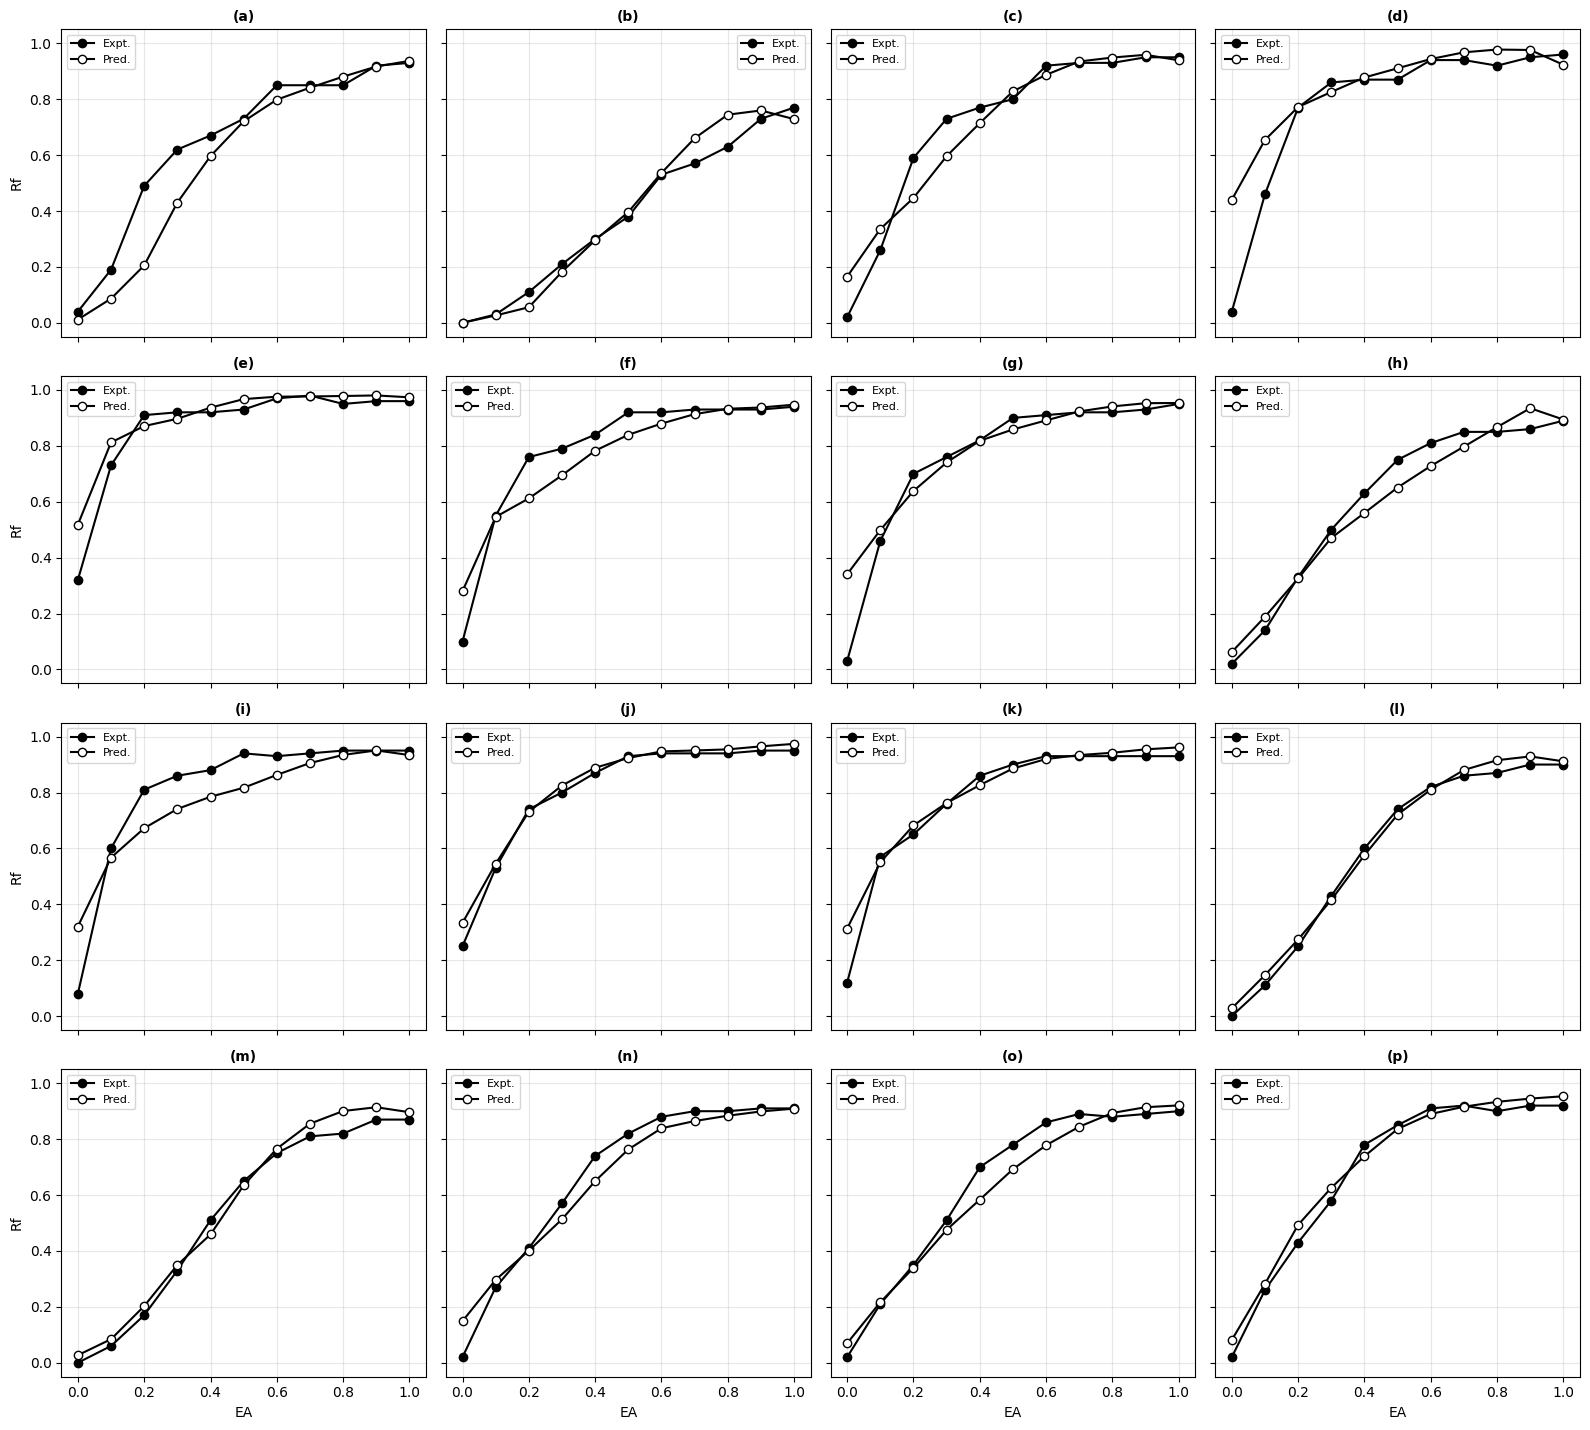

In [7]:
plot_functional(result1, n_cols=4)

## Figure 5

Figure 5(a): 1,2,3,4  
Figure 5(b): 5,6  
Figure 5(c): 7, 8

In [8]:
input_csv = os.path.join(DTLC_ROOT, 'Predictive_models/model_validation', 'pred_list2.csv')
result2 = predict_vol_ratio_csv(input_csv, output_csv='./DB/Rf/pred_result2.csv')
result2.head(15)

>>> making graph...


Processing...


  0%|          | 0/38 [00:00<?, ?it/s]

Done!
Processing...


  0%|          | 0/38 [00:00<?, ?it/s]

Done!
Processing...


  0%|          | 0/38 [00:00<?, ?it/s]

>>> collecting: compound, eluent graph...
>>> making: dataloader...
>>> predicting...
>> Done!
>> saved: ./DB/Rf/pred_result2.csv


Done!


,Smiles,elu1_smiles,elu2_smiles,ratio1,ratio2,Rf,BLI_GAT_Rf
0,CC(=O)c1ccc(C(C)(C)C)cc1,CCCCCC,CCOC(C)=O,0.833333,0.166667,0.66394,0.682815
1,CC(=O)c1ccc(C(C)(C)C)cc1,CCCCCC,CCOC(C)=O,0.750000,0.250000,0.79018,0.761784
2,CC(=O)c1ccc(C(C)(C)C)cc1,CCCCCC,CCOC(C)=O,0.500000,0.500000,0.91622,0.910690
3,CC(=O)c1ccc(C(C)(C)C)cc1,CCCCCC,CCOC(C)=O,0.333333,0.666667,0.95498,0.950221
4,CC(=O)c1ccc(C(C)=O)cc1,CCCCCC,CCOC(C)=O,0.833333,0.166667,0.28494,0.309956
5,CC(=O)c1ccc(C(C)=O)cc1,CCCCCC,CCOC(C)=O,0.750000,0.250000,0.42039,0.458103
6,CC(=O)c1ccc(C(C)=O)cc1,CCCCCC,CCOC(C)=O,0.500000,0.500000,0.77016,0.731730
7,CC(=O)c1ccc(C(C)=O)cc1,CCCCCC,CCOC(C)=O,0.333333,0.666667,0.85766,0.831305
8,CC(=O)c1ccc(O)cc1,CCCCCC,CCOC(C)=O,0.833333,0.166667,0.10638,0.125470
9,CC(=O)c1ccc(O)cc1,CCCCCC,CCOC(C)=O,0.750000,0.250000,0.22106,0.239405


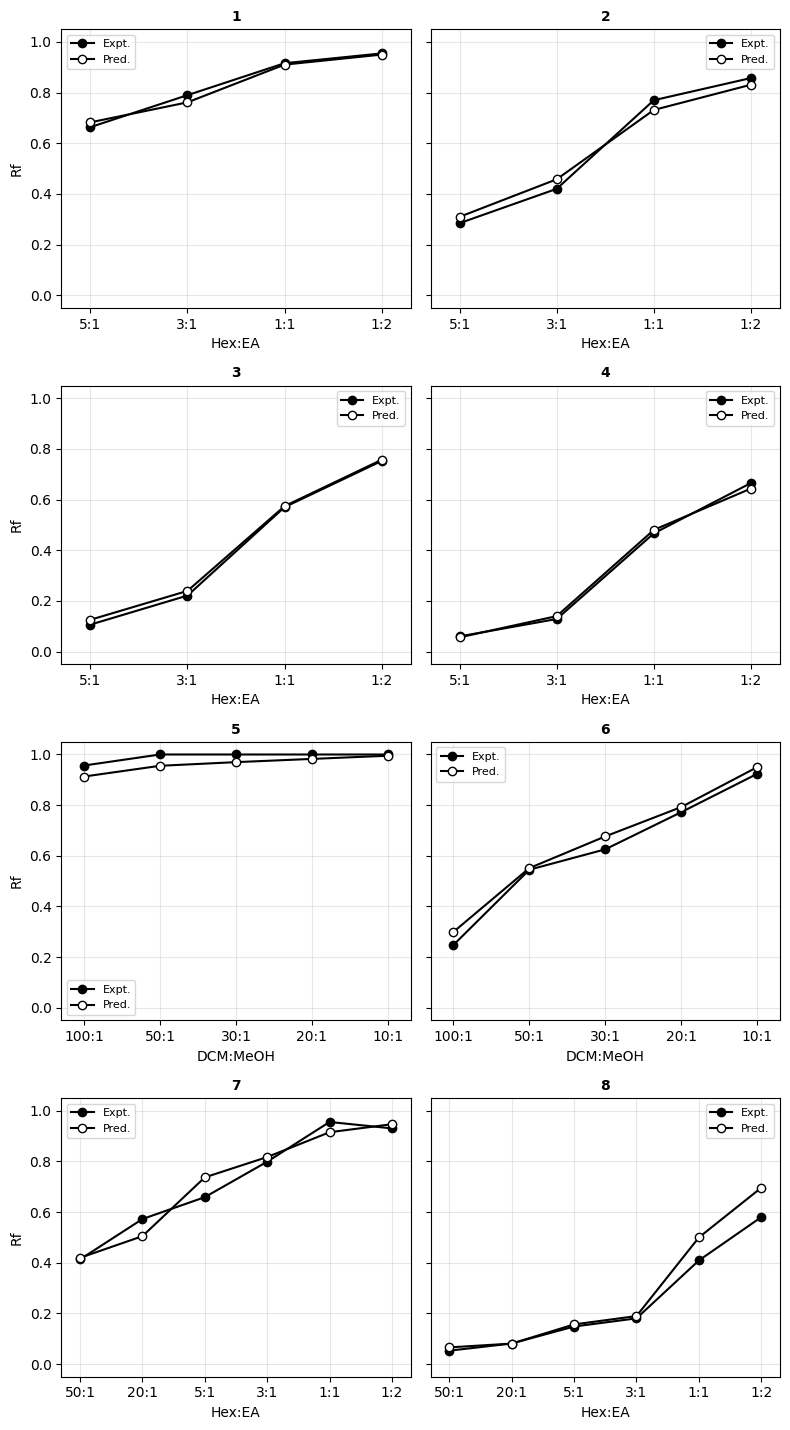

In [9]:
plot_solvent(result2, n_cols=2)